In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
import matplotlib.ticker as ticker


In [2]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="up32ez2814",
    database="ecommerce_bi_project"
)

In [3]:
orders = pd.read_sql("SELECT * FROM orders_clean", connection)
customers = pd.read_sql("SELECT * FROM customers_clean", connection)
products = pd.read_sql("SELECT * FROM products_clean", connection)

print(orders.shape)
print(customers.shape)
print(products.shape)

C:\Users\SHIKHAR SINGH\AppData\Local\Temp\ipykernel_6628\83632412.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orders = pd.read_sql("SELECT * FROM orders_clean", connection)


(44930, 11)
(4000, 6)
(800, 4)


C:\Users\SHIKHAR SINGH\AppData\Local\Temp\ipykernel_6628\83632412.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customers = pd.read_sql("SELECT * FROM customers_clean", connection)
C:\Users\SHIKHAR SINGH\AppData\Local\Temp\ipykernel_6628\83632412.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  products = pd.read_sql("SELECT * FROM products_clean", connection)


In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 44930 entries, 0 to 44929
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      44930 non-null  str    
 1   Order_Date    44930 non-null  object 
 2   Ship_Date     44820 non-null  object 
 3   Customer_ID   44901 non-null  str    
 4   Product_ID    44910 non-null  str    
 5   Quantity      44930 non-null  int64  
 6   Sales         44930 non-null  float64
 7   Discount      44930 non-null  float64
 8   Profit        44930 non-null  float64
 9   Ship_Mode     44930 non-null  str    
 10  Payment_Mode  44831 non-null  str    
dtypes: float64(3), int64(1), object(2), str(5)
memory usage: 3.8+ MB


In [5]:
orders.isnull().sum()

Order_ID          0
Order_Date        0
Ship_Date       110
Customer_ID      29
Product_ID       20
Quantity          0
Sales             0
Discount          0
Profit            0
Ship_Mode         0
Payment_Mode     99
dtype: int64

In [6]:
orders.describe()

,Quantity,Sales,Discount,Profit
count,44930.000000,44930.000000,44930.000000,44930.000000
mean,3.220076,1189.473309,0.159544,80.394087
std,2.042025,1532.570099,0.096238,165.927040
min,1.000000,3.740000,0.000600,-1072.830000
25%,2.000000,270.257500,0.085400,7.690000
50%,3.000000,643.520000,0.143400,34.355000
75%,4.000000,1461.125000,0.217300,98.157500
max,10.000000,17008.450000,0.637000,2831.640000


In [7]:
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])
orders["Ship_Date"] = pd.to_datetime(orders["Ship_Date"])

orders.dtypes

Order_ID                  str
Order_Date      datetime64[s]
Ship_Date       datetime64[s]
Customer_ID               str
Product_ID                str
Quantity                int64
Sales                 float64
Discount              float64
Profit                float64
Ship_Mode                 str
Payment_Mode              str
dtype: object

In [8]:
orders[["Quantity", "Sales", "Discount", "Profit"]].describe()

,Quantity,Sales,Discount,Profit
count,44930.000000,44930.000000,44930.000000,44930.000000
mean,3.220076,1189.473309,0.159544,80.394087
std,2.042025,1532.570099,0.096238,165.927040
min,1.000000,3.740000,0.000600,-1072.830000
25%,2.000000,270.257500,0.085400,7.690000
50%,3.000000,643.520000,0.143400,34.355000
75%,4.000000,1461.125000,0.217300,98.157500
max,10.000000,17008.450000,0.637000,2831.640000


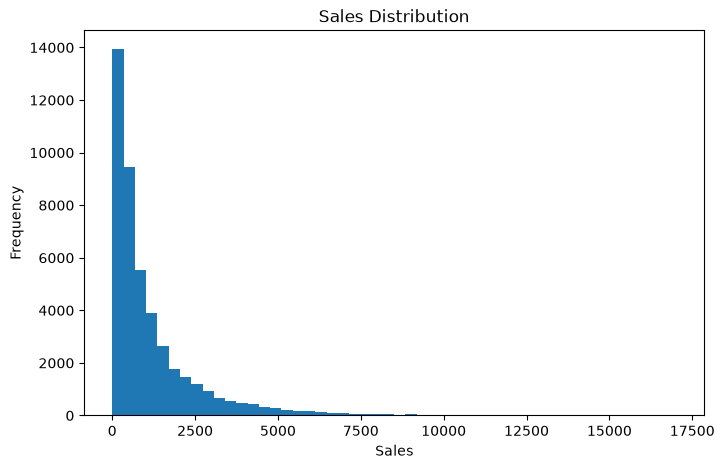

In [9]:
# ============================================================
# Sales Distribution
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(orders["Sales"], bins=50)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

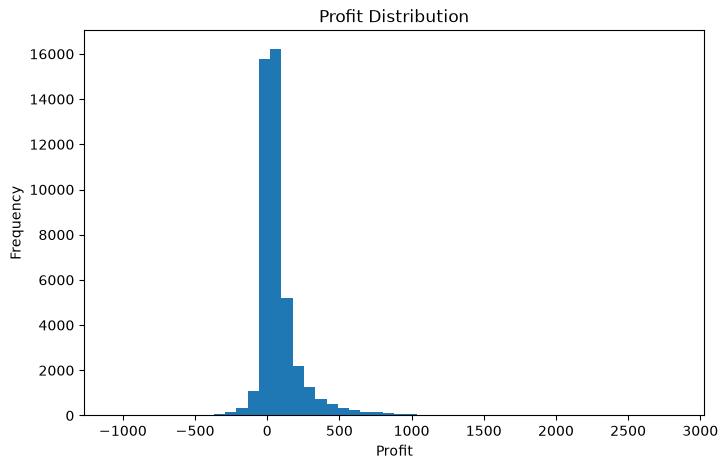

In [10]:
# ============================================================
# Profit Distribution
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(orders["Profit"], bins=50)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.show()

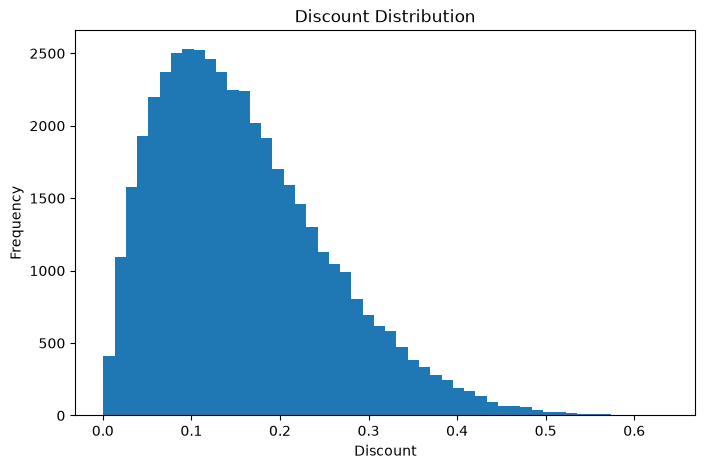

In [11]:
# ============================================================
# Discount Distribution
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(orders["Discount"], bins=50)

plt.title("Discount Distribution")
plt.xlabel("Discount")
plt.ylabel("Frequency")

plt.show()

In [12]:
# ============================================================
# Quantity Distribution
# ============================================================

quantity_distribution = (
    orders["Quantity"]
    .value_counts()
    .sort_index()
)

quantity_distribution

Quantity
1      9793
2     10696
3      8116
4      5891
5      4028
6      2729
7      1785
8      1174
10      718
Name: count, dtype: int64

In [13]:
# ============================================================
# Order Distribution by Category
# ============================================================

category_distribution = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )["Category"]
    .value_counts(dropna=False)
)

category_distribution

Category
Electronics        10541
Office Supplies     9740
Home & Kitchen      9219
Furniture           8203
Clothing            6969
NaN                  258
Name: count, dtype: int64

In [14]:
# ============================================================
# Sales by Category
# ============================================================

category_sales = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Electronics        26584944.45
Furniture          10720469.92
Home & Kitchen      9177526.45
Clothing            3476298.35
Office Supplies     3378724.92
Name: Sales, dtype: float64

In [15]:
# ============================================================
# Profit by Category
# ============================================================

category_profit = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Category
Electronics        2060127.34
Home & Kitchen      525713.96
Office Supplies     396874.47
Clothing            313421.63
Furniture           311229.54
Name: Profit, dtype: float64

In [16]:
# ============================================================
# Profit Margin by Category
# ============================================================

category_summary = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

category_summary["Profit_Margin_%"] = (
    category_summary["Profit"] /
    category_summary["Sales"] * 100
).round(2)

category_summary.sort_values(
    "Profit_Margin_%",
    ascending=False
)

,Sales,Profit,Profit_Margin_%
Category,,,
Office Supplies,3378724.92,396874.47,11.75
Clothing,3476298.35,313421.63,9.02
Electronics,26584944.45,2060127.34,7.75
Home & Kitchen,9177526.45,525713.96,5.73
Furniture,10720469.92,311229.54,2.90


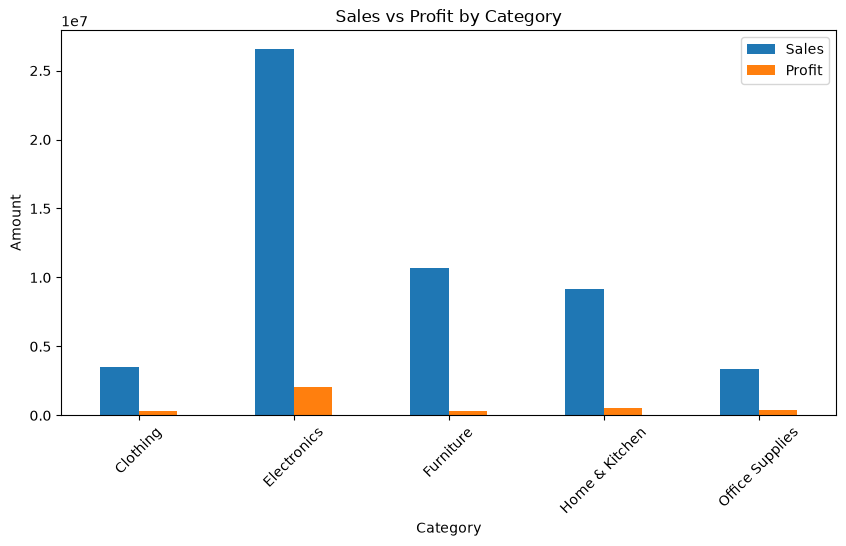

In [17]:
# ============================================================
# Sales vs Profit by Category
# ============================================================

category_summary[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sales vs Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)

plt.show()

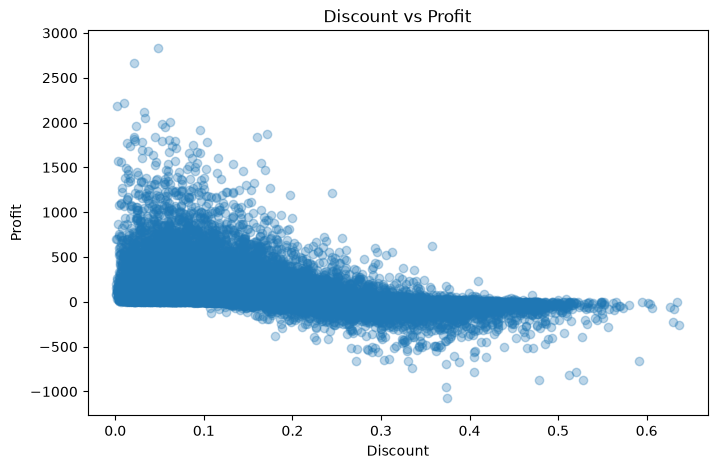

In [18]:
# ============================================================
# Discount vs Profit Relationship
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    orders["Discount"],
    orders["Profit"],
    alpha=0.3
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

In [19]:
# ============================================================
# Regional Sales, Profit & Orders Analysis
# ============================================================

region_summary = (
    orders
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
)

region_summary["Profit_Margin_%"] = (
    region_summary["Profit"] /
    region_summary["Sales"] * 100
).round(2)

region_summary.sort_values(
    "Sales",
    ascending=False
)

,Sales,Profit,Orders,Profit_Margin_%
Region,,,,
North,21283968.92,1436494.21,18138,6.75
South,13482421.12,899216.32,11358,6.67
West,11374891.89,767006.92,9239,6.74
East,7269644.32,507584.36,6166,6.98


In [20]:
# ============================================================
# Customer Segment Performance
# ============================================================

segment_summary = (
    orders
    .merge(
        customers[["Customer_ID", "Segment"]],
        on="Customer_ID",
        how="left"
    )
    .groupby("Segment")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
)

segment_summary["Profit_Margin_%"] = (
    segment_summary["Profit"] /
    segment_summary["Sales"] * 100
).round(2)

segment_summary.sort_values(
    "Sales",
    ascending=False
)

,Sales,Profit,Orders,Profit_Margin_%
Segment,,,,
Consumer,34368041.64,2318928.03,28760,6.75
Corporate,11621582.24,784231.79,9805,6.75
Home Office,6891281.08,469181.76,5875,6.81


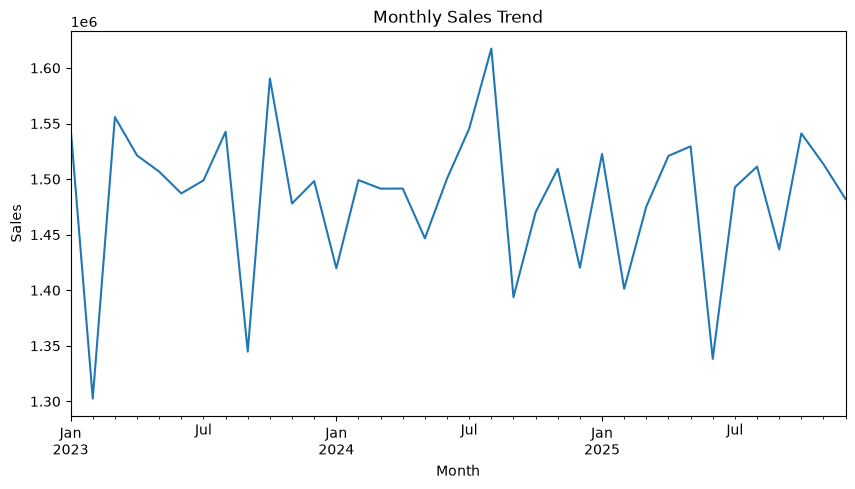

In [21]:
# ============================================================
# Monthly Sales Trend
# ============================================================

monthly_sales = (
    orders
    .groupby(
        orders["Order_Date"].dt.to_period("M")
    )["Sales"]
    .sum()
)

monthly_sales.plot(figsize=(10, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

In [22]:
# ============================================================
# Yearly Sales & Profit Analysis
# ============================================================

yearly_summary = (
    orders
    .groupby(
        orders["Order_Date"].dt.to_period("Y")
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values(
        "Total_Sales",
        ascending=False
    )
)

yearly_summary

,Total_Sales,Total_Profit
Order_Date,,
2023,17872659.69,1209458.50
2024,17805210.56,1198029.82
2025,17765165.51,1204618.00


In [23]:
# ============================================================
# Customer with Highest Total Sales
# ============================================================

customer_sales = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

customer_sales.head(1)

Customer_ID
CUST02241    45852.31
Name: Sales, dtype: float64

In [24]:
# ============================================================
# Customer with Highest Total Profit
# ============================================================

customer_profit = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

customer_profit.head(1)

Customer_ID
CUST03303    6057.37
Name: Profit, dtype: float64

In [25]:
# ============================================================
# Customer with Highest Number of Orders
# ============================================================

customer_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Order_ID"]
    .nunique()
    .sort_values(ascending=False)
)

customer_orders.head(1)

Customer_ID
CUST03269    23
Name: Order_ID, dtype: int64

In [26]:
# ============================================================
# Customer Average Order Value (AOV)
# ============================================================

customer_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

customer_summary["AOV"] = (
    customer_summary["Total_Sales"] /
    customer_summary["Total_Orders"]
)

customer_summary.sort_values(
    "AOV",
    ascending=False
).head(1)

,Total_Sales,Total_Orders,AOV
Customer_ID,,,
CUST01783,17381.84,5,3476.368


In [27]:
# ============================================================
# Customer with Highest Total Quantity Purchased
# ============================================================

customer_qty = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

customer_qty.head(1)

Customer_ID
CUST00744    91
Name: Quantity, dtype: int64

In [28]:
# ============================================================
# Customer with Highest Profit Margin
# ============================================================

customer_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

customer_summary["Profit_Margin_Pct"] = (
    customer_summary["Total_Profit"] /
    customer_summary["Total_Sales"] * 100
)

customer_summary.sort_values(
    "Profit_Margin_Pct",
    ascending=False
).head(1)

,Total_Sales,Total_Profit,Profit_Margin_Pct
Customer_ID,,,
CUST02517,16305.69,2543.88,15.60118


In [29]:
# ============================================================
# Customer with Highest Cumulative Discount Rate
# ============================================================

customer_discount = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Discount"]
    .sum()
    .sort_values(ascending=False)
)

customer_discount.head(1)

Customer_ID
CUST02810    4.8726
Name: Discount, dtype: float64

In [30]:
# ============================================================
# Customer with Highest Average Discount
# ============================================================

customer_avg_discount = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Discount"]
    .mean()
    .sort_values(ascending=False)
)

customer_avg_discount.head(1)

Customer_ID
CUST02695    0.3012
Name: Discount, dtype: float64

In [31]:
# ============================================================
# Customer with Highest Number of Distinct Products Purchased
# ============================================================

customer_products_count = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Product_ID"]
    .nunique()
    .sort_values(ascending=False)
)

customer_products_count.head(1)

Customer_ID
CUST03269    23
Name: Product_ID, dtype: int64

In [32]:
# ============================================================
# Customer with Highest Average Profit per Order
# ============================================================

customer_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

customer_summary["Avg_Profit_Per_Order"] = (
    customer_summary["Total_Profit"] /
    customer_summary["Total_Orders"]
)

customer_summary.sort_values(
    "Avg_Profit_Per_Order",
    ascending=False
).head(1)

,Total_Profit,Total_Orders,Avg_Profit_Per_Order
Customer_ID,,,
CUST03303,6057.37,12,504.780833


In [33]:
# ============================================================
# Product with Highest Total Sales
# ============================================================

product_sales = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Sales=("Sales", "sum")
    )
    .sort_values(
        "Total_Sales",
        ascending=False
    )
)

product_sales.head(1)

,Total_Sales
Product_ID,
PROD00410,209042.59


In [34]:
# ============================================================
# Product with Highest Total Profit
# ============================================================

product_profit = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Profit=("Profit", "sum")
    )
    .sort_values(
        "Total_Profit",
        ascending=False
    )
)

product_profit.head(1)

,Total_Profit
Product_ID,
PROD00578,17290.84


In [35]:
# ============================================================
# Product with Highest Total Quantity Sold
# ============================================================

product_qty = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Qty=("Quantity", "sum")
    )
    .sort_values(
        "Total_Qty",
        ascending=False
    )
)

product_qty.head(1)

,Total_Qty
Product_ID,
PROD00030,285


In [36]:
# ============================================================
# Product with Highest Average Selling Price per Unit
# ============================================================

product_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Qty=("Quantity", "sum")
    )
)

product_summary["Avg_Sales_Per_Unit"] = (
    product_summary["Total_Sales"] /
    product_summary["Total_Qty"]
)

product_summary.sort_values(
    "Avg_Sales_Per_Unit",
    ascending=False
).head(1)

,Total_Sales,Total_Qty,Avg_Sales_Per_Unit
Product_ID,,,
PROD00436,169979.22,173,982.538844


In [37]:
# ============================================================
# Product with Highest Profit Margin
# ============================================================

product_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

product_summary["Profit_Margin_Pct"] = (
    product_summary["Total_Profit"] /
    product_summary["Total_Sales"] * 100
)

product_summary.sort_values(
    "Profit_Margin_Pct",
    ascending=False
).head(1)

,Total_Sales,Total_Profit,Profit_Margin_Pct
Product_ID,,,
PROD00715,23823.49,3713.19,15.586255


In [38]:
# ============================================================
# Product with Highest Average Discount
# ============================================================

product_avg_discount = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")["Discount"]
    .mean()
    .sort_values(ascending=False)
)

product_avg_discount.head(1)

Product_ID
PROD00181    0.20606
Name: Discount, dtype: float64

In [39]:
# ============================================================
# Product with Highest Number of Orders
# ============================================================

product_order = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")["Order_ID"]
    .nunique()
    .sort_values(ascending=False)
)

product_order.head(1)

Product_ID
PROD00030    79
Name: Order_ID, dtype: int64

In [40]:
# ============================================================
# Product with Highest Average Profit per Order
# ============================================================

product_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .groupby("Product_ID")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

product_summary["Avg_Profit_Per_Order"] = (
    product_summary["Total_Profit"] /
    product_summary["Total_Orders"]
)

product_summary.sort_values(
    "Avg_Profit_Per_Order",
    ascending=False
).head(1)

,Total_Profit,Total_Orders,Avg_Profit_Per_Order
Product_ID,,,
PROD00250,15478.36,51,303.497255


In [41]:
# ============================================================
# Category with Highest Average Order Value (AOV)
# ============================================================

category_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

category_summary["AOV"] = (
    category_summary["Total_Sales"] /
    category_summary["Total_Orders"]
)

category_summary.sort_values(
    "AOV",
    ascending=False
).head(1)

,Total_Sales,Total_Orders,AOV
Category,,,
Electronics,26584944.45,10541,2522.051461


In [42]:
# ============================================================
# Category with Highest Average Profit per Order
# ============================================================

category_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

category_summary["Avg_Profit_Per_Order"] = (
    category_summary["Total_Profit"] /
    category_summary["Total_Orders"]
)

category_summary.sort_values(
    "Avg_Profit_Per_Order",
    ascending=False
).head(1)

,Total_Profit,Total_Orders,Avg_Profit_Per_Order
Category,,,
Electronics,2060127.34,10541,195.439459


In [43]:
# ============================================================
# Category with Highest Average Quantity per Order
# ============================================================

category_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Qty=("Quantity", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

category_summary["Avg_Qty_Per_Order"] = (
    category_summary["Total_Qty"] /
    category_summary["Total_Orders"]
)

category_summary.sort_values(
    "Avg_Qty_Per_Order",
    ascending=False
).head(1)

,Total_Qty,Total_Orders,Avg_Qty_Per_Order
Category,,,
Home & Kitchen,29758,9219,3.227899


In [44]:
# ============================================================
# Category with Highest Average Discount
# ============================================================

category_avg_discount = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Avg_Discount=("Discount", "mean")
    )
)

category_avg_discount.sort_values(
    "Avg_Discount",
    ascending=False
).head(1)

,Avg_Discount
Category,
Home & Kitchen,0.161036


In [45]:
# ============================================================
# Category with Highest Profit Margin
# ============================================================

category_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum")
    )
)

category_summary["Profit_Margin_Pct"] = (
    category_summary["Total_Profit"] /
    category_summary["Total_Sales"] * 100
)

category_summary.sort_values(
    "Profit_Margin_Pct",
    ascending=False
).head(1)

,Total_Profit,Total_Sales,Profit_Margin_Pct
Category,,,
Office Supplies,396874.47,3378724.92,11.746279


In [46]:
# ============================================================
# Category with Highest Number of Distinct Products Sold
# ============================================================

category_product_count = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Products=("Product_ID", "nunique")
    )
)

category_product_count.sort_values(
    "Total_Products",
    ascending=False
).head(1)

,Total_Products
Category,
Electronics,186


In [47]:
# ============================================================
# Category with Highest Number of Unique Customers
# ============================================================

category_customers_count = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Customers=("Customer_ID", "nunique")
    )
)

category_customers_count.sort_values(
    "Total_Customers",
    ascending=False
).head(1)

,Total_Customers
Category,
Electronics,3719


In [48]:
# ============================================================
# Category with Highest Repeat-Customer Rate
# ============================================================

category_customer_orders = (
    orders
    .dropna(subset=["Customer_ID", "Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby(["Category", "Customer_ID"])
    .agg(
        Customer_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

category_repeat = (
    category_customer_orders
    .groupby("Category")
    .agg(
        Total_Customers=("Customer_ID", "nunique"),
        Repeat_Customers=("Customer_Orders", lambda x: (x > 1).sum())
    )
)

category_repeat["Repeat_Customer_Rate_Pct"] = (
    category_repeat["Repeat_Customers"] /
    category_repeat["Total_Customers"] * 100
)

category_repeat.sort_values(
    "Repeat_Customer_Rate_Pct",
    ascending=False
).head(1)

,Total_Customers,Repeat_Customers,Repeat_Customer_Rate_Pct
Category,,,
Electronics,3719,2969,79.833289


In [49]:
# ============================================================
# Category with Highest Average Quantity Purchased per Customer
# ============================================================

category_customer_qty = (
    orders
    .dropna(subset=["Customer_ID", "Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby(["Category", "Customer_ID"])
    .agg(
        Total_Qty=("Quantity", "sum")
    )
    .reset_index()
)

category_avg_qty = (
    category_customer_qty
    .groupby("Category")
    .agg(
        Avg_Qty_Per_Customer=("Total_Qty", "mean")
    )
)

category_avg_qty.sort_values(
    "Avg_Qty_Per_Customer",
    ascending=False
).head(1)

,Avg_Qty_Per_Customer
Category,
Electronics,9.119118


In [50]:
# ============================================================
# Category with Highest Average Sales per Customer
# ============================================================

category_customer_sales = (
    orders
    .dropna(subset=["Customer_ID", "Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby(["Category", "Customer_ID"])
    .agg(
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

category_avg_sales = (
    category_customer_sales
    .groupby("Category")
    .agg(
        Avg_Sales_Per_Customer=("Total_Sales", "mean")
    )
)

category_avg_sales.sort_values(
    "Avg_Sales_Per_Customer",
    ascending=False
).head(1)

,Avg_Sales_Per_Customer
Category,
Electronics,7144.56285


In [51]:
# ============================================================
# Category with Highest Average Profit per Customer
# ============================================================

category_customer_profit = (
    orders
    .dropna(subset=["Customer_ID", "Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby(["Category", "Customer_ID"])
    .agg(
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

category_avg_profit = (
    category_customer_profit
    .groupby("Category")
    .agg(
        Avg_Profit_Per_Customer=("Total_Profit", "mean")
    )
)

category_avg_profit.sort_values(
    "Avg_Profit_Per_Customer",
    ascending=False
).head(1)

,Avg_Profit_Per_Customer
Category,
Electronics,553.804281


In [52]:
# ============================================================
# Category with Highest Profit Contribution to Total Profit
# ============================================================

category_summary = (
    orders
    .dropna(subset=["Product_ID"])
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

category_summary["Profit_Contribution_Pct"] = (
    category_summary["Total_Profit"] /
    orders["Profit"].sum() * 100
)

category_summary.sort_values(
    "Profit_Contribution_Pct",
    ascending=False
).head(1)

,Category,Total_Profit,Profit_Contribution_Pct
1,Electronics,2060127.34,57.033962


In [53]:
# ============================================================
# Region with Highest Total Sales
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

region_summary.sort_values(
    "Total_Sales",
    ascending=False
).head(1)

,Region,Total_Sales
1,North,21283968.92


In [54]:
# ============================================================
# Region with Highest Total Profit
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_summary.sort_values(
    "Total_Profit",
    ascending=False
).head(1)

,Region,Total_Profit
1,North,1436494.21


In [55]:
# ============================================================
# Region with Highest Profit Margin
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

region_summary["Profit_Margin_Pct"] = (
    region_summary["Total_Profit"] /
    region_summary["Total_Sales"] * 100
)

region_summary.sort_values(
    "Profit_Margin_Pct",
    ascending=False
).head(1)

,Region,Total_Profit,Total_Sales,Profit_Margin_Pct
0,East,507584.36,7269644.32,6.982245


In [56]:
# ============================================================
# Region with Highest Average Order Value (AOV)
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

region_summary["Avg_Order_Value"] = (
    region_summary["Total_Sales"] /
    region_summary["Total_Orders"]
)

region_summary.sort_values(
    "Avg_Order_Value",
    ascending=False
).head(1)

,Region,Total_Orders,Total_Sales,Avg_Order_Value
3,West,9239,11374891.89,1231.182151


In [57]:
# ============================================================
# Region with Highest Average Quantity per Order
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Qty=("Quantity", "sum")
    )
    .reset_index()
)

region_summary["Avg_Qty_Per_Order"] = (
    region_summary["Total_Qty"] /
    region_summary["Total_Orders"]
)

region_summary.sort_values(
    "Avg_Qty_Per_Order",
    ascending=False
).head(1)

,Region,Total_Orders,Total_Qty,Avg_Qty_Per_Order
3,West,9239,30096,3.257495


In [58]:
# ============================================================
# Region with Highest Average Discount
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Avg_Discount=("Discount", "mean")
    )
    .reset_index()
)

region_summary.sort_values(
    "Avg_Discount",
    ascending=False
).head(1)

,Region,Avg_Discount
2,South,0.160464


In [59]:
# ============================================================
# Region with Highest Number of Unique Customers
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Unique_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
)

region_summary.sort_values(
    "Unique_Customers",
    ascending=False
).head(1)

,Region,Unique_Customers
1,North,1617


In [60]:
# ============================================================
# Region with Highest Total Quantity Sold
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Qty=("Quantity", "sum")
    )
    .reset_index()
)

region_summary.sort_values(
    "Total_Qty",
    ascending=False
).head(1)

,Region,Total_Qty
1,North,58115


In [61]:
# ============================================================
# Region with Highest Average Profit per Order
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_summary["Avg_Profit_Per_Order"] = (
    region_summary["Total_Profit"] /
    region_summary["Total_Orders"]
)

region_summary.sort_values(
    "Avg_Profit_Per_Order",
    ascending=False
).head(1)

,Region,Total_Orders,Total_Profit,Avg_Profit_Per_Order
3,West,9239,767006.92,83.018392


In [62]:

# ============================================================
# Region with Highest Average Profit per Customer
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "nunique"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_summary["Avg_Profit_Per_Customer"] = (
    region_summary["Total_Profit"] /
    region_summary["Total_Customers"]
)

region_summary.sort_values(
    "Avg_Profit_Per_Customer",
    ascending=False
).head(1)

,Region,Total_Customers,Total_Profit,Avg_Profit_Per_Customer
3,West,818,767006.92,937.661271


In [63]:

# ============================================================
# Region with Highest Average Sales per Customer
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "nunique"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

region_summary["Avg_Sales_Per_Customer"] = (
    region_summary["Total_Sales"] /
    region_summary["Total_Customers"]
)

region_summary.sort_values(
    "Avg_Sales_Per_Customer",
    ascending=False
).head(1)

,Region,Total_Customers,Total_Sales,Avg_Sales_Per_Customer
3,West,818,11374891.89,13905.735807


In [64]:
# ============================================================
# Region with Highest Repeat-Customer Rate
# ============================================================

region_customer_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby(["Region", "Customer_ID"])
    .agg(
        Customer_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

region_repeat = (
    region_customer_orders
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "nunique"),
        Repeat_Customers=("Customer_Orders", lambda x: (x > 1).sum())
    )
    .reset_index()
)

region_repeat["Repeat_Customer_Rate_Pct"] = (
    region_repeat["Repeat_Customers"] /
    region_repeat["Total_Customers"] * 100
)

region_repeat.sort_values(
    "Repeat_Customer_Rate_Pct",
    ascending=False
).head(1)

,Region,Total_Customers,Repeat_Customers,Repeat_Customer_Rate_Pct
0,East,552,552,100.0


In [65]:
# ============================================================
# Region with Highest Number of Distinct Products Purchased
# ============================================================

region_summary = (
    orders
    .dropna(subset=["Customer_ID", "Product_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Products=("Product_ID", "nunique")
    )
    .reset_index()
)

region_summary.sort_values(
    "Total_Products",
    ascending=False
).head(1)

,Region,Total_Products
0,East,800


In [66]:
# ============================================================
# Region with Highest Percentage of High-Discount Orders
# High Discount = Discount > 20%
# ============================================================

region_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
)

region_discount = (
    region_orders
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        High_Discount_Orders=(
            "Discount",
            lambda x: (x > 0.20).sum()
        )
    )
    .reset_index()
)

region_discount["High_Discount_Rate_Pct"] = (
    region_discount["High_Discount_Orders"] /
    region_discount["Total_Orders"] * 100
)

region_discount.sort_values(
    "High_Discount_Rate_Pct",
    ascending=False
).head(1)

,Region,Total_Orders,High_Discount_Orders,High_Discount_Rate_Pct
2,South,11358,3411,30.031696


In [67]:
# ============================================================
# Region with Highest Percentage of Loss-Making Orders
# Loss-Making Order = Profit < 0
# ============================================================

region_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
)

region_profit = (
    region_orders
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Loss_Making_Orders=(
            "Profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

region_profit["Loss_Making_Order_Rate_Pct"] = (
    region_profit["Loss_Making_Orders"] /
    region_profit["Total_Orders"] * 100
)

region_profit.sort_values(
    "Loss_Making_Order_Rate_Pct",
    ascending=False
).head(1)

,Region,Total_Orders,Loss_Making_Orders,Loss_Making_Order_Rate_Pct
2,South,11358,1829,16.103187


In [68]:
# ============================================================
# Region with Highest Estimated Discount Amount
# Estimated Discount Amount = Sales × Discount
# ============================================================

region_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
)

region_orders["Discount_Amount"] = (
    region_orders["Sales"] *
    region_orders["Discount"]
)

region_discount = (
    region_orders
    .groupby("Region")
    .agg(
        Total_Discount_Amount=("Discount_Amount", "sum")
    )
    .reset_index()
)

region_discount.sort_values(
    "Total_Discount_Amount",
    ascending=False
).head(1)

,Region,Total_Discount_Amount
1,North,3.170121e+06


In [69]:
# ============================================================
# Region with Highest Profit Contribution Percentage
# ============================================================

region_profit = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_profit["Profit_Contribution_Pct"] = (
    region_profit["Total_Profit"] /
    region_profit["Total_Profit"].sum() * 100
)

region_profit.sort_values(
    "Profit_Contribution_Pct",
    ascending=False
).head(1)

,Region,Total_Profit,Profit_Contribution_Pct
1,North,1436494.21,39.788757


In [70]:
# ============================================================
# Region with Highest Sales Contribution Percentage
# ============================================================

region_sales = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

region_sales["Sales_Contribution_Pct"] = (
    region_sales["Total_Sales"] /
    region_sales["Total_Sales"].sum() * 100
)

region_sales.sort_values(
    "Sales_Contribution_Pct",
    ascending=False
).head(1)

,Region,Total_Sales,Sales_Contribution_Pct
1,North,21283968.92,39.849466


In [71]:
# ============================================================
# Region with Highest Profit Margin among High-Discount Orders
# High Discount = Discount > 20%
# ============================================================

high_discount_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .query("Discount > 0.20")
)

region_high_discount = (
    high_discount_orders
    .groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_high_discount["Profit_Margin_Pct"] = (
    region_high_discount["Total_Profit"] /
    region_high_discount["Total_Sales"] * 100
)

region_high_discount.sort_values(
    "Profit_Margin_Pct",
    ascending=False
).head(1)


,Region,Total_Sales,Total_Profit,Profit_Margin_Pct
3,West,2964622.42,893.61,0.030142


In [72]:
# ============================================================
# Region with Highest Average Order Value among High-Discount Orders
# High Discount = Discount > 20%
# ============================================================

high_discount_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .dropna(subset=["Region"])
    .query("Discount > 0.20")
)

region_high_discount = (
    high_discount_orders
    .groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

region_high_discount["Avg_Order_Value"] = (
    region_high_discount["Total_Sales"] /
    region_high_discount["Total_Orders"]
)

region_high_discount.sort_values(
    "Avg_Order_Value",
    ascending=False
).head(1)

,Region,Total_Sales,Total_Orders,Avg_Order_Value
3,West,2964622.42,2726,1087.535737


In [73]:
# ============================================================
# Customer First Purchase Month
# ============================================================

customer_first_purchase = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")
    .agg(
        First_Purchase_Date=("Order_Date", "min")
    )
    .reset_index()
)

customer_first_purchase["First_Purchase_Month"] = (
    customer_first_purchase["First_Purchase_Date"]
    .dt.to_period("M")
)

customer_first_purchase.head()

,Customer_ID,First_Purchase_Date,First_Purchase_Month
0,CUST00001,2023-03-04,2023-03
1,CUST00002,2023-09-07,2023-09
2,CUST00003,2023-02-06,2023-02
3,CUST00004,2023-04-16,2023-04
4,CUST00005,2023-03-23,2023-03


In [74]:
# ============================================================
# Cohort Q2: Attach Cohort Month to Every Order
# ============================================================
orders["Order_Month"] = orders["Order_Date"].dt.to_period("M")

cohort_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .merge(
        customer_first_purchase[
            ["Customer_ID", "First_Purchase_Month"]
        ],
        on="Customer_ID",
        how="left"
    )
    .rename(
        columns={
            "First_Purchase_Month": "Cohort_Month"
        }
    )
)

cohort_orders[
    ["Customer_ID", "Order_Date", "Order_Month", "Cohort_Month"]
].head()

,Customer_ID,Order_Date,Order_Month,Cohort_Month
0,CUST02193,2023-09-13,2023-09,2023-03
1,CUST00559,2023-02-02,2023-02,2023-02
2,CUST00792,2023-11-16,2023-11,2023-04
3,CUST01202,2024-05-26,2024-05,2023-04
4,CUST01749,2023-07-03,2023-07,2023-02


In [75]:
# ============================================================
# Cohort Q3: Calculate Month Number
# ============================================================
cohort_orders["Month_Number"] = (
    (cohort_orders["Order_Month"].dt.year -
     cohort_orders["Cohort_Month"].dt.year) * 12
    +
    (cohort_orders["Order_Month"].dt.month -
     cohort_orders["Cohort_Month"].dt.month)
)


cohort_orders[
    [
        "Customer_ID",
        "Order_Month",
        "Cohort_Month",
        "Month_Number"
    ]
].head(10)

,Customer_ID,Order_Month,Cohort_Month,Month_Number
0,CUST02193,2023-09,2023-03,6
1,CUST00559,2023-02,2023-02,0
2,CUST00792,2023-11,2023-04,7
3,CUST01202,2024-05,2023-04,13
4,CUST01749,2023-07,2023-02,5
5,CUST00360,2024-03,2023-01,14
6,CUST00285,2024-08,2023-07,13
7,CUST03317,2024-09,2023-01,20
8,CUST02813,2024-02,2023-07,7
9,CUST03278,2023-03,2023-03,0


In [76]:
# ============================================================
# Cohort Q4: Active Customers by Cohort Month & Month Number
# ============================================================

cohort_retention = (
    cohort_orders
    .groupby(
        ["Cohort_Month", "Month_Number"]
    )["Customer_ID"]
    .nunique()
    .reset_index(name="Active_Customers")
)

cohort_retention.head(15)

,Cohort_Month,Month_Number,Active_Customers
0,2023-01,0,1094
1,2023-01,1,263
2,2023-01,2,300
3,2023-01,3,306
4,2023-01,4,299
5,2023-01,5,291
6,2023-01,6,319
7,2023-01,7,304
8,2023-01,8,268
9,2023-01,9,324


In [77]:
# ============================================================
# Cohort Q5: Calculate Cohort Size & Retention Percentage
# ============================================================

cohort_size = (
    cohort_retention[
        cohort_retention["Month_Number"] == 0
    ][["Cohort_Month", "Active_Customers"]]
    .rename(
        columns={
            "Active_Customers": "Cohort_Size"
        }
    )
)

cohort_retention = cohort_retention.merge(
    cohort_size,
    on="Cohort_Month",
    how="left"
)

cohort_retention["Retention_Pct"] = (
    cohort_retention["Active_Customers"]
    / cohort_retention["Cohort_Size"]
    * 100
).round(2)

cohort_retention.head(15)

,Cohort_Month,Month_Number,Active_Customers,Cohort_Size,Retention_Pct
0,2023-01,0,1094,1094,100.00
1,2023-01,1,263,1094,24.04
2,2023-01,2,300,1094,27.42
3,2023-01,3,306,1094,27.97
4,2023-01,4,299,1094,27.33
5,2023-01,5,291,1094,26.60
6,2023-01,6,319,1094,29.16
7,2023-01,7,304,1094,27.79
8,2023-01,8,268,1094,24.50
9,2023-01,9,324,1094,29.62


In [78]:
# ============================================================
# Cohort Q6: Create Cohort Retention Matrix
# ============================================================

cohort_retention_matrix = (
    cohort_retention
    .pivot(
        index="Cohort_Month",
        columns="Month_Number",
        values="Retention_Pct"
    )
)

cohort_retention_matrix

Month_Number,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
Cohort_Month,,,,,,,,,,,,,,,,,,,,,
2023-01,100.0,24.04,27.42,27.97,27.33,26.60,29.16,27.79,24.50,29.62,...,26.23,25.23,26.69,25.50,26.42,26.69,27.70,26.51,27.33,25.23
2023-02,100.0,28.34,26.60,28.05,26.16,25.44,26.60,27.03,25.58,25.73,...,24.56,27.76,24.42,26.60,29.07,27.76,26.60,29.80,30.81,NaN
2023-03,100.0,27.41,29.20,25.77,24.80,29.20,23.16,26.59,23.65,27.08,...,27.90,27.08,26.10,27.24,24.96,31.00,28.55,24.31,NaN,NaN
2023-04,100.0,26.60,28.08,26.11,26.11,26.85,28.82,29.56,28.82,26.60,...,21.67,27.34,28.08,26.60,27.83,28.08,27.34,NaN,NaN,NaN
2023-05,100.0,29.18,23.93,24.59,29.51,27.54,26.56,27.54,29.18,27.54,...,28.52,24.92,26.23,23.61,27.21,25.90,NaN,NaN,NaN,NaN
2023-06,100.0,26.94,29.39,24.08,26.53,26.94,33.47,29.80,21.63,25.71,...,31.84,21.63,26.12,22.86,31.02,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,25.41,23.76,25.97,29.83,22.65,30.39,27.07,27.62,27.07,...,23.76,26.52,24.31,30.39,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,28.00,27.20,26.40,31.20,28.00,24.80,24.00,26.40,27.20,...,28.00,32.80,25.60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,26.88,20.43,24.73,25.81,22.58,31.18,25.81,20.43,19.35,...,32.26,27.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


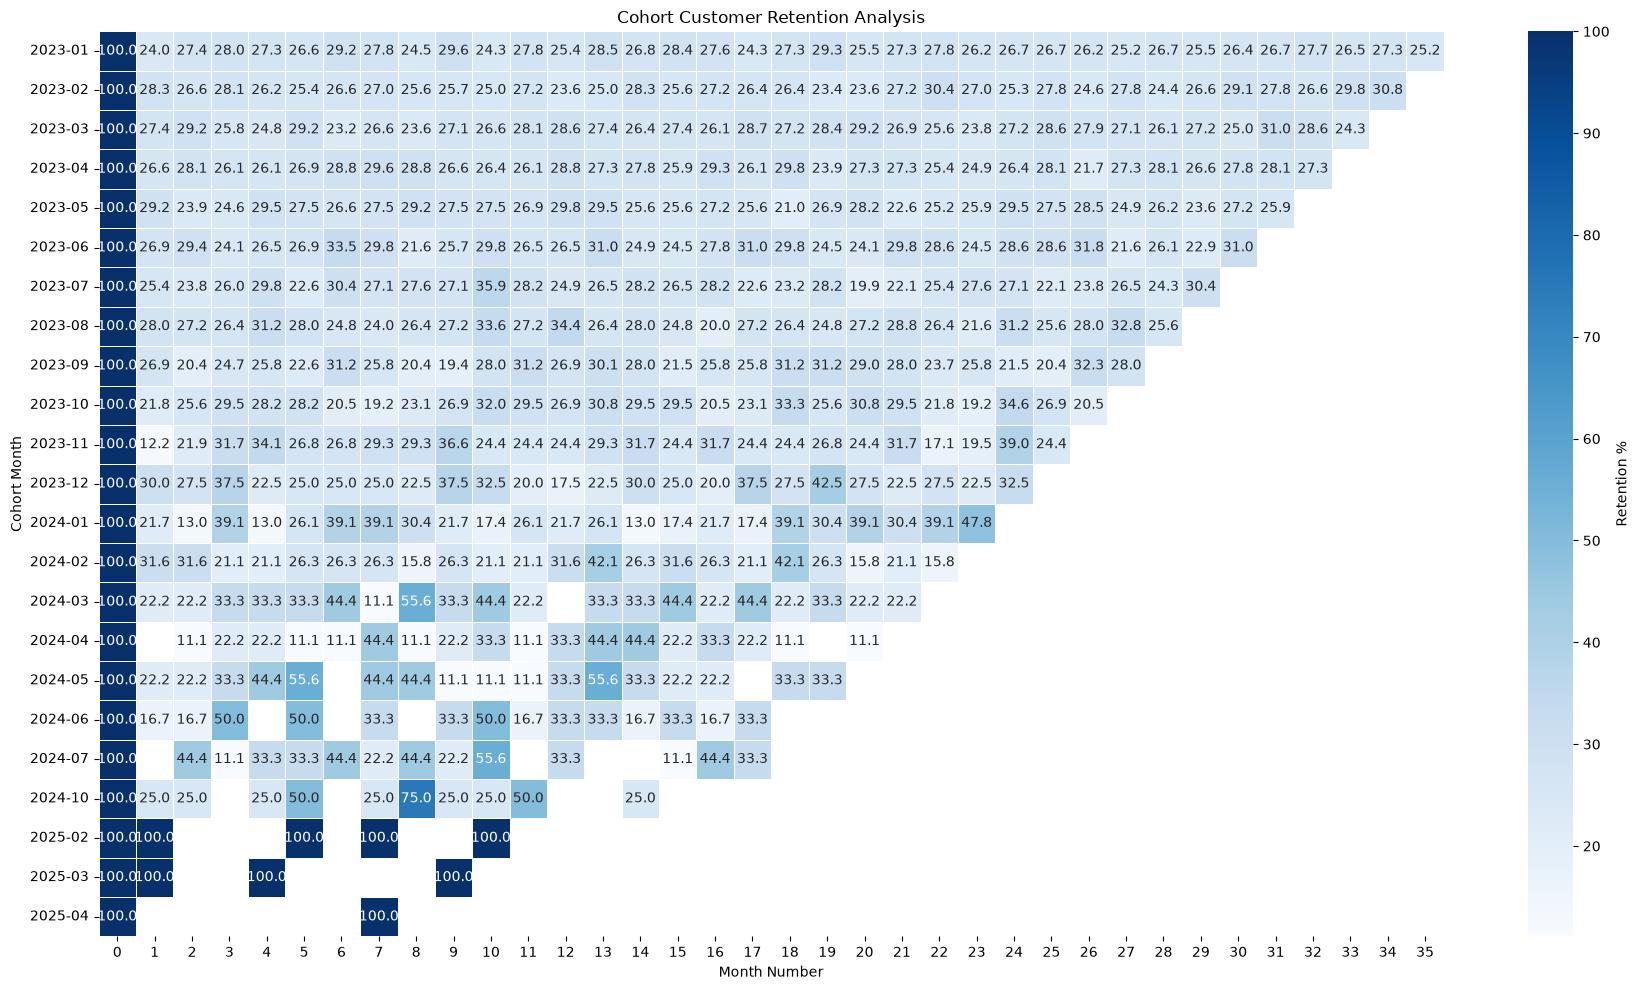

In [79]:
# ============================================================
# Cohort Q7: Cohort Retention Heatmap
# ============================================================

plt.figure(figsize=(18, 10))

sns.heatmap(
    cohort_retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Retention %"}
)

plt.title("Cohort Customer Retention Analysis")
plt.xlabel("Month Number")
plt.ylabel("Cohort Month")

plt.tight_layout()
plt.show()

In [80]:
# ============================================================
# Cohort Q8: Overall Month-1 Retention Rate
# ============================================================

month_1_retention = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 1,
        "Retention_Pct"
    ]
    .mean()
)

print(f"Overall Month-1 Retention Rate: {month_1_retention:.2f}%")

Overall Month-1 Retention Rate: 32.31%


In [81]:
# ============================================================
# Cohort Q9: Cohort with Highest Month-1 Retention
# ============================================================

month_1 = cohort_retention[
    cohort_retention["Month_Number"] == 1
]

highest_month_1_retention = month_1.loc[
    month_1["Retention_Pct"].idxmax()
]

print("Best Cohort:", highest_month_1_retention["Cohort_Month"])
print(
    f"Month-1 Retention: "
    f"{highest_month_1_retention['Retention_Pct']:.2f}%"
)

Best Cohort: 2025-02
Month-1 Retention: 100.00%


In [82]:
# ============================================================
# Cohort Q10: Cohort with Highest Month-3 Retention
# ============================================================

month_3 = cohort_retention[
    cohort_retention["Month_Number"] == 3
]

highest_month_3_retention = month_3.loc[
    month_3["Retention_Pct"].idxmax()
]

print("Best Cohort:", highest_month_3_retention["Cohort_Month"])
print(
    f"Month-3 Retention: "
    f"{highest_month_3_retention['Retention_Pct']:.2f}%"
)

Best Cohort: 2024-06
Month-3 Retention: 50.00%


In [83]:
# ============================================================
# Cohort Q11: Overall Month-3 Retention Rate
# ============================================================

month_3_retention = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 3,
        "Retention_Pct"
    ]
    .mean()
)

print(
    f"Overall Month-3 Retention Rate: "
    f"{month_3_retention:.2f}%"
)

Overall Month-3 Retention Rate: 28.55%


In [84]:
# ============================================================
# Cohort Q12: Overall Month-6 Retention Rate
# ============================================================

month_6_retention = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 6,
        "Retention_Pct"
    ]
    .mean()
)

print(
    f"Overall Month-6 Retention Rate: "
    f"{month_6_retention:.2f}%"
)

Overall Month-6 Retention Rate: 28.94%


In [85]:
# ============================================================
# Cohort Q13: Cohort with Highest Month-6 Retention
# ============================================================

month_6 = cohort_retention[
    cohort_retention["Month_Number"] == 6
]

highest_month_6_retention = month_6.loc[
    month_6["Retention_Pct"].idxmax()
]

print("Best Cohort:", highest_month_6_retention["Cohort_Month"])
print(
    f"Month-6 Retention: "
    f"{highest_month_6_retention['Retention_Pct']:.2f}%"
)

Best Cohort: 2024-03
Month-6 Retention: 44.44%


In [86]:
# ============================================================
# Cohort Q14: Compare Month-1, Month-3 & Month-6 Retention
# ============================================================

retention_comparison = (
    cohort_retention[
        cohort_retention["Month_Number"].isin([1, 3, 6])
    ]
    .groupby("Month_Number")["Retention_Pct"]
    .mean()
    .reset_index()
)

retention_comparison.columns = [
    "Month_Number",
    "Average_Retention_Pct"
]

print(retention_comparison)

   Month_Number  Average_Retention_Pct
0             1              32.311000
1             3              28.554737
2             6              28.936471


In [87]:
# ============================================================
# Cohort Q15: Retention Change from Month-1 to Month-6
# ============================================================

month_1_avg = (
    cohort_retention.loc[
        cohort_retention["Month_Number"] == 1,
        "Retention_Pct"
    ].mean()
)

month_6_avg = (
    cohort_retention.loc[
        cohort_retention["Month_Number"] == 6,
        "Retention_Pct"
    ].mean()
)

retention_change = month_6_avg - month_1_avg

print(f"Month-1 Retention: {month_1_avg:.2f}%")
print(f"Month-6 Retention: {month_6_avg:.2f}%")
print(f"Retention Change: {retention_change:.2f} percentage points")

Month-1 Retention: 32.31%
Month-6 Retention: 28.94%
Retention Change: -3.37 percentage points


In [88]:
# ============================================================
# Cohort Q16: Strongest Long-Term Retention Cohort
# ============================================================

month_6 = cohort_retention[
    cohort_retention["Month_Number"] == 6
]

strongest_long_term_cohort = month_6.loc[
    month_6["Retention_Pct"].idxmax()
]

print(
    "Strongest Long-Term Cohort:",
    strongest_long_term_cohort["Cohort_Month"]
)

print(
    f"Month-6 Retention: "
    f"{strongest_long_term_cohort['Retention_Pct']:.2f}%"
)

Strongest Long-Term Cohort: 2024-03
Month-6 Retention: 44.44%


In [89]:
# ============================================================
# Cohort Q17: Month-1 to Month-6 Retention Trend by Cohort
# ============================================================

cohort_trend = (
    cohort_retention[
        cohort_retention["Month_Number"].isin([1, 2, 3, 4, 5, 6])
    ]
    .pivot(
        index="Cohort_Month",
        columns="Month_Number",
        values="Retention_Pct"
    )
)

# Rename columns for readability
cohort_trend.columns = [
    f"Month_{int(col)}_Retention"
    for col in cohort_trend.columns
]

cohort_trend

,Month_1_Retention,Month_2_Retention,Month_3_Retention,Month_4_Retention,Month_5_Retention,Month_6_Retention
Cohort_Month,,,,,,
2023-01,24.04,27.42,27.97,27.33,26.60,29.16
2023-02,28.34,26.60,28.05,26.16,25.44,26.60
2023-03,27.41,29.20,25.77,24.80,29.20,23.16
2023-04,26.60,28.08,26.11,26.11,26.85,28.82
2023-05,29.18,23.93,24.59,29.51,27.54,26.56
2023-06,26.94,29.39,24.08,26.53,26.94,33.47
2023-07,25.41,23.76,25.97,29.83,22.65,30.39
2023-08,28.00,27.20,26.40,31.20,28.00,24.80
2023-09,26.88,20.43,24.73,25.81,22.58,31.18


In [90]:
# ============================================================
# Cohort Q18: Largest Retention Drop from Month-1 to Month-6
# ============================================================

cohort_drop = (
    cohort_trend
    .dropna(
        subset=[
            "Month_1_Retention",
            "Month_6_Retention"
        ]
    )
    .copy()
)

# Calculate retention drop
cohort_drop["Retention_Drop"] = (
    cohort_drop["Month_1_Retention"]
    - cohort_drop["Month_6_Retention"]
)

# Find cohort with the largest drop
largest_drop = cohort_drop.loc[
    cohort_drop["Retention_Drop"].idxmax()
]

print("Cohort:", largest_drop.name)
print(
    f"Month-1 Retention: "
    f"{largest_drop['Month_1_Retention']:.2f}%"
)
print(
    f"Month-6 Retention: "
    f"{largest_drop['Month_6_Retention']:.2f}%"
)
print(
    f"Retention Drop: "
    f"{largest_drop['Retention_Drop']:.2f} percentage points"
)

Cohort: 2024-02
Month-1 Retention: 31.58%
Month-6 Retention: 26.32%
Retention Drop: 5.26 percentage points


In [91]:
# ============================================================
# Cohort Q19: Overall Average Retention Drop
# ============================================================

eligible_cohorts = cohort_trend.dropna(
    subset=[
        "Month_1_Retention",
        "Month_6_Retention"
    ]
).copy()

eligible_cohorts["Retention_Drop"] = (
    eligible_cohorts["Month_1_Retention"]
    - eligible_cohorts["Month_6_Retention"]
)

average_retention_drop = (
    eligible_cohorts["Retention_Drop"]
    .mean()
)

print(
    f"Average Retention Drop from Month-1 to Month-6: "
    f"{average_retention_drop:.2f} percentage points"
)

Average Retention Drop from Month-1 to Month-6: -3.60 percentage points


In [92]:
# ============================================================
# Cohort Q20: Overall Percentage Change in Retention
# ============================================================

month_1_avg = (
    cohort_retention.loc[
        cohort_retention["Month_Number"] == 1,
        "Retention_Pct"
    ].mean()
)

month_6_avg = (
    cohort_retention.loc[
        cohort_retention["Month_Number"] == 6,
        "Retention_Pct"
    ].mean()
)

percentage_change = (
    (month_6_avg - month_1_avg)
    / month_1_avg
    * 100
)

print(f"Month-1 Retention: {month_1_avg:.2f}%")
print(f"Month-6 Retention: {month_6_avg:.2f}%")
print(f"Percentage Change: {percentage_change:.2f}%")

Month-1 Retention: 32.31%
Month-6 Retention: 28.94%
Percentage Change: -10.44%


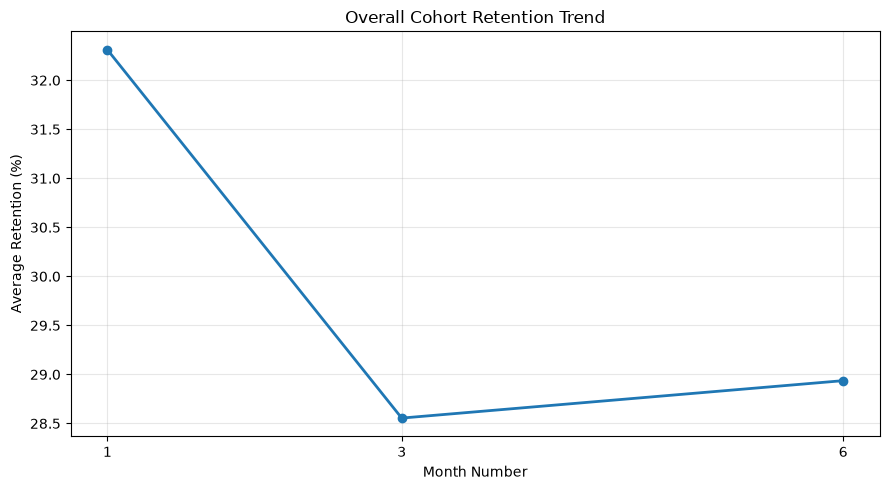

In [93]:
# ============================================================
# Cohort Q21: Month-1, Month-3 & Month-6 Retention Trend
# ============================================================

retention_trend = (
    cohort_retention[
        cohort_retention["Month_Number"].isin([1, 3, 6])
    ]
    .groupby("Month_Number")["Retention_Pct"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    retention_trend["Month_Number"],
    retention_trend["Retention_Pct"],
    marker="o",
    linewidth=2
)

plt.xticks([1, 3, 6])

plt.title("Overall Cohort Retention Trend")
plt.xlabel("Month Number")
plt.ylabel("Average Retention (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
# ============================================================
# Cohort Q22: Month-1 Retention by Cohort
# ============================================================

month_1_by_cohort = (
    cohort_retention[
        cohort_retention["Month_Number"] == 1
    ][
        ["Cohort_Month", "Retention_Pct"]
    ]
    .sort_values(
        "Cohort_Month"
    )
)

print(month_1_by_cohort)

    Cohort_Month  Retention_Pct
1        2023-01          24.04
37       2023-02          28.34
72       2023-03          27.41
106      2023-04          26.60
139      2023-05          29.18
171      2023-06          26.94
202      2023-07          25.41
232      2023-08          28.00
261      2023-09          26.88
289      2023-10          21.79
316      2023-11          12.20
342      2023-12          30.00
367      2024-01          21.74
391      2024-02          31.58
414      2024-03          22.22
454      2024-05          22.22
472      2024-06          16.67
501      2024-10          25.00
512      2025-02         100.00
517      2025-03         100.00


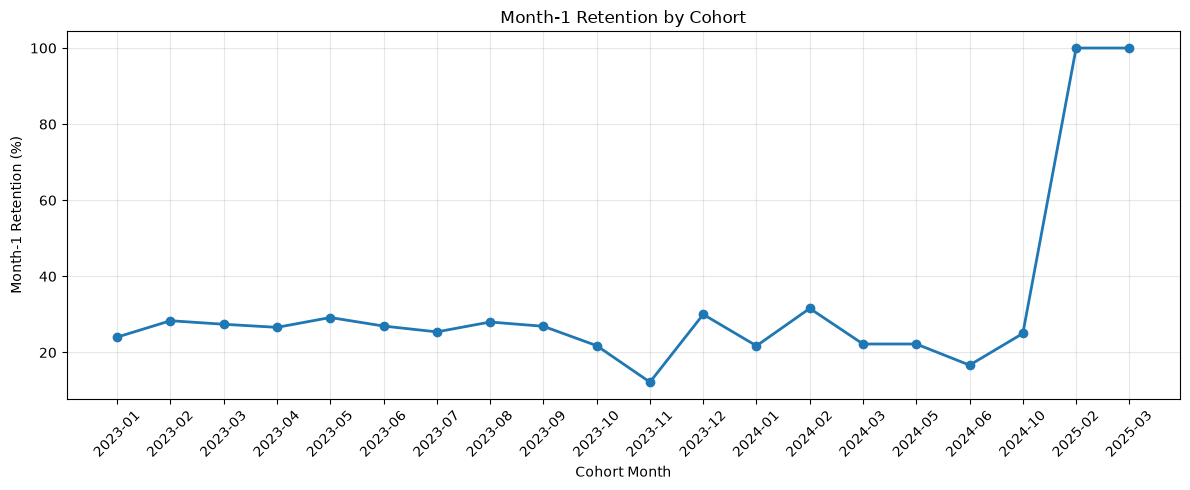

In [95]:
# ============================================================
# Cohort Q22: Month-1 Retention by Cohort - Line Chart
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    month_1_by_cohort["Cohort_Month"].astype(str),
    month_1_by_cohort["Retention_Pct"],
    marker="o",
    linewidth=2
)

plt.title("Month-1 Retention by Cohort")
plt.xlabel("Cohort Month")
plt.ylabel("Month-1 Retention (%)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [96]:
# ============================================================
# Cohort Q23: Highest & Lowest Month-1 Retention Cohort
# ============================================================

month_1 = cohort_retention[
    cohort_retention["Month_Number"] == 1
].copy()

# Highest Month-1 retention
highest_month_1 = month_1.loc[
    month_1["Retention_Pct"].idxmax()
]

# Lowest Month-1 retention
lowest_month_1 = month_1.loc[
    month_1["Retention_Pct"].idxmin()
]

print("Highest Month-1 Retention")
print("Cohort:", highest_month_1["Cohort_Month"])
print(
    f"Retention: "
    f"{highest_month_1['Retention_Pct']:.2f}%"
)

print("\nLowest Month-1 Retention")
print("Cohort:", lowest_month_1["Cohort_Month"])
print(
    f"Retention: "
    f"{lowest_month_1['Retention_Pct']:.2f}%"
)

Highest Month-1 Retention
Cohort: 2025-02
Retention: 100.00%

Lowest Month-1 Retention
Cohort: 2023-11
Retention: 12.20%


In [97]:
# ============================================================
# Cohort Q24: Highest & Lowest Month-3 Retention Cohort
# ============================================================

month_3 = cohort_retention[
    cohort_retention["Month_Number"] == 3
].copy()

# Highest Month-3 retention
highest_month_3 = month_3.loc[
    month_3["Retention_Pct"].idxmax()
]

# Lowest Month-3 retention
lowest_month_3 = month_3.loc[
    month_3["Retention_Pct"].idxmin()
]

print("Highest Month-3 Retention")
print("Cohort:", highest_month_3["Cohort_Month"])
print(
    f"Retention: "
    f"{highest_month_3['Retention_Pct']:.2f}%"
)

print("\nLowest Month-3 Retention")
print("Cohort:", lowest_month_3["Cohort_Month"])
print(
    f"Retention: "
    f"{lowest_month_3['Retention_Pct']:.2f}%"
)

Highest Month-3 Retention
Cohort: 2024-06
Retention: 50.00%

Lowest Month-3 Retention
Cohort: 2024-07
Retention: 11.11%


In [98]:
# ============================================================
# Cohort Q25: Highest & Lowest Month-6 Retention Cohort
# ============================================================

month_6 = cohort_retention[
    cohort_retention["Month_Number"] == 6
].copy()

# Highest Month-6 retention
highest_month_6 = month_6.loc[
    month_6["Retention_Pct"].idxmax()
]

# Lowest Month-6 retention
lowest_month_6 = month_6.loc[
    month_6["Retention_Pct"].idxmin()
]

print("Highest Month-6 Retention")
print("Cohort:", highest_month_6["Cohort_Month"])
print(
    f"Retention: "
    f"{highest_month_6['Retention_Pct']:.2f}%"
)

print("\nLowest Month-6 Retention")
print("Cohort:", lowest_month_6["Cohort_Month"])
print(
    f"Retention: "
    f"{lowest_month_6['Retention_Pct']:.2f}%"
)

Highest Month-6 Retention
Cohort: 2024-03
Retention: 44.44%

Lowest Month-6 Retention
Cohort: 2024-04
Retention: 11.11%


In [99]:
# ============================================================
# Cohort Q26: Most Consistent Retention Cohort
# ============================================================

cohort_consistency = (
    cohort_trend
    .dropna(
        subset=[
            "Month_1_Retention",
            "Month_2_Retention",
            "Month_3_Retention",
            "Month_4_Retention",
            "Month_5_Retention",
            "Month_6_Retention"
        ]
    )
    .copy()
)

retention_columns = [
    "Month_1_Retention",
    "Month_2_Retention",
    "Month_3_Retention",
    "Month_4_Retention",
    "Month_5_Retention",
    "Month_6_Retention"
]

cohort_consistency["Retention_Std"] = (
    cohort_consistency[retention_columns]
    .std(axis=1)
)

most_consistent_cohort = cohort_consistency.loc[
    cohort_consistency["Retention_Std"].idxmin()
]

print("Most Consistent Cohort:", most_consistent_cohort.name)
print(
    f"Retention Standard Deviation: "
    f"{most_consistent_cohort['Retention_Std']:.2f}"
)

print("\nRetention Trend:")
print(
    most_consistent_cohort[retention_columns]
)

Most Consistent Cohort: 2023-04
Retention Standard Deviation: 1.11

Retention Trend:
Month_1_Retention    26.60
Month_2_Retention    28.08
Month_3_Retention    26.11
Month_4_Retention    26.11
Month_5_Retention    26.85
Month_6_Retention    28.82
Name: 2023-04, dtype: float64


In [100]:
# ============================================================
# Cohort Q27: Most Volatile Retention Cohort
# ============================================================

cohort_volatility = (
    cohort_trend
    .dropna(
        subset=[
            "Month_1_Retention",
            "Month_2_Retention",
            "Month_3_Retention",
            "Month_4_Retention",
            "Month_5_Retention",
            "Month_6_Retention"
        ]
    )
    .copy()
)

retention_columns = [
    "Month_1_Retention",
    "Month_2_Retention",
    "Month_3_Retention",
    "Month_4_Retention",
    "Month_5_Retention",
    "Month_6_Retention"
]

cohort_volatility["Retention_Std"] = (
    cohort_volatility[retention_columns]
    .std(axis=1)
)

most_volatile_cohort = cohort_volatility.loc[
    cohort_volatility["Retention_Std"].idxmax()
]

print("Most Volatile Cohort:", most_volatile_cohort.name)
print(
    f"Retention Standard Deviation: "
    f"{most_volatile_cohort['Retention_Std']:.2f}"
)

print("\nRetention Trend:")
print(
    most_volatile_cohort[retention_columns]
)

Most Volatile Cohort: 2024-01
Retention Standard Deviation: 11.80

Retention Trend:
Month_1_Retention    21.74
Month_2_Retention    13.04
Month_3_Retention    39.13
Month_4_Retention    13.04
Month_5_Retention    26.09
Month_6_Retention    39.13
Name: 2024-01, dtype: float64


In [101]:
# ============================================================
# Cohort Q28: Cohorts with Improved Month-1 to Month-6 Retention
# ============================================================

cohort_improvement = (
    cohort_trend
    .dropna(
        subset=[
            "Month_1_Retention",
            "Month_6_Retention"
        ]
    )
    .copy()
)

cohort_improvement["Retention_Change"] = (
    cohort_improvement["Month_6_Retention"]
    - cohort_improvement["Month_1_Retention"]
)

improved_cohorts = cohort_improvement[
    cohort_improvement["Retention_Change"] > 0
].copy()

print("Cohorts with Improved Retention:")
print(
    improved_cohorts[
        [
            "Month_1_Retention",
            "Month_6_Retention",
            "Retention_Change"
        ]
    ]
)

Cohorts with Improved Retention:
              Month_1_Retention  Month_6_Retention  Retention_Change
Cohort_Month                                                        
2023-01                   24.04              29.16              5.12
2023-04                   26.60              28.82              2.22
2023-06                   26.94              33.47              6.53
2023-07                   25.41              30.39              4.98
2023-09                   26.88              31.18              4.30
2023-11                   12.20              26.83             14.63
2024-01                   21.74              39.13             17.39
2024-03                   22.22              44.44             22.22


In [102]:
# ============================================================
# Cohort Q29: Retention Improvement / Decline / No Change
# ============================================================

cohort_status = (
    cohort_trend
    .dropna(
        subset=[
            "Month_1_Retention",
            "Month_6_Retention"
        ]
    )
    .copy()
)

cohort_status["Retention_Change"] = (
    cohort_status["Month_6_Retention"]
    - cohort_status["Month_1_Retention"]
)

cohort_status["Retention_Status"] = (
    cohort_status["Retention_Change"]
    .apply(
        lambda x:
            "Improved" if x > 0
            else "Declined" if x < 0
            else "Unchanged"
    )
)

status_summary = (
    cohort_status["Retention_Status"]
    .value_counts()
    .reindex(
        ["Improved", "Declined", "Unchanged"],
        fill_value=0
    )
    .reset_index()
)

status_summary.columns = [
    "Retention_Status",
    "Cohort_Count"
]

print(status_summary)

  Retention_Status  Cohort_Count
0         Improved             8
1         Declined             7
2        Unchanged             0


In [103]:
# ============================================================
# Cohort Q30: Retention Status Percentage Distribution
# ============================================================

status_percentage = status_summary.copy()

total_cohorts = status_percentage["Cohort_Count"].sum()

status_percentage["Percentage"] = (
    status_percentage["Cohort_Count"]
    / total_cohorts
    * 100
).round(2)

print(status_percentage)

  Retention_Status  Cohort_Count  Percentage
0         Improved             8       53.33
1         Declined             7       46.67
2        Unchanged             0        0.00


In [104]:
# ============================================================
# Cohort Q31: Overall Retention Trend - Business Interpretation
# ============================================================

retention_summary = (
    cohort_retention[
        cohort_retention["Month_Number"].isin([1, 3, 6])
    ]
    .groupby("Month_Number")["Retention_Pct"]
    .mean()
    .round(2)
)

print("Month-1 Retention:", retention_summary.get(1), "%")
print("Month-3 Retention:", retention_summary.get(3), "%")
print("Month-6 Retention:", retention_summary.get(6), "%")

month_1 = retention_summary.get(1)
month_3 = retention_summary.get(3)
month_6 = retention_summary.get(6)

print("\nBusiness Interpretation:")

if month_6 < month_3 < month_1:
    print(
        "Retention declines consistently from Month-1 to Month-6, "
        "indicating customer retention weakens over time."
    )
elif month_6 < month_1:
    print(
        "Month-6 retention is lower than Month-1, "
        "indicating an overall long-term retention decline."
    )
elif month_6 > month_1:
    print(
        "Month-6 retention is higher than Month-1, "
        "indicating an overall improvement in long-term retention."
    )
else:
    print(
        "Month-6 retention is approximately equal to Month-1, "
        "indicating relatively stable long-term retention."
    )

Month-1 Retention: 32.31 %
Month-3 Retention: 28.55 %
Month-6 Retention: 28.94 %

Business Interpretation:
Month-6 retention is lower than Month-1, indicating an overall long-term retention decline.


In [105]:
# ============================================================
# Cohort Q32: Final Cohort Business Insights
# ============================================================

month_1 = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 1,
        "Retention_Pct"
    ]
    .mean()
)

month_3 = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 3,
        "Retention_Pct"
    ]
    .mean()
)

month_6 = (
    cohort_retention
    .loc[
        cohort_retention["Month_Number"] == 6,
        "Retention_Pct"
    ]
    .mean()
)

month_1_to_3_change = month_3 - month_1
month_3_to_6_change = month_6 - month_3
month_1_to_6_change = month_6 - month_1

print("COHORT RETENTION BUSINESS INSIGHTS")
print("=" * 55)

print(f"Month-1 Retention: {month_1:.2f}%")
print(f"Month-3 Retention: {month_3:.2f}%")
print(f"Month-6 Retention: {month_6:.2f}%")

print(
    f"\nMonth-1 to Month-3 Change: "
    f"{month_1_to_3_change:.2f} percentage points"
)

print(
    f"Month-3 to Month-6 Change: "
    f"{month_3_to_6_change:.2f} percentage points"
)

print(
    f"Month-1 to Month-6 Change: "
    f"{month_1_to_6_change:.2f} percentage points"
)

print("\nBusiness Interpretation:")

if month_6 < month_1:
    print(
        "Overall long-term retention declined from Month-1 "
        "to Month-6."
    )

if month_6 > month_3:
    print(
        "Retention stabilized and slightly improved "
        "between Month-3 and Month-6."
    )
elif month_6 < month_3:
    print(
        "Retention continued to decline between "
        "Month-3 and Month-6."
    )
else:
    print(
        "Retention remained unchanged between "
        "Month-3 and Month-6."
    )

COHORT RETENTION BUSINESS INSIGHTS
Month-1 Retention: 32.31%
Month-3 Retention: 28.55%
Month-6 Retention: 28.94%

Month-1 to Month-3 Change: -3.76 percentage points
Month-3 to Month-6 Change: 0.38 percentage points
Month-1 to Month-6 Change: -3.37 percentage points

Business Interpretation:
Overall long-term retention declined from Month-1 to Month-6.
Retention stabilized and slightly improved between Month-3 and Month-6.


In [106]:
# ============================================================
# Business Investigation Q1:
# Highest Sales Category vs Highest Profit Margin
# ============================================================

category_analysis = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Category", dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
    * 100
)

highest_sales_category = category_analysis.loc[
    category_analysis["Total_Sales"].idxmax()
]

highest_margin_category = category_analysis.loc[
    category_analysis["Profit_Margin"].idxmax()
]

print("Highest Sales Category:")
print(
    highest_sales_category[
        ["Category", "Total_Sales", "Profit_Margin"]
    ]
)

print("\nHighest Profit Margin Category:")
print(
    highest_margin_category[
        ["Category", "Total_Sales", "Profit_Margin"]
    ]
)

Highest Sales Category:
Category         Electronics
Total_Sales      26584944.45
Profit_Margin       7.749226
Name: 1, dtype: object

Highest Profit Margin Category:
Category         Office Supplies
Total_Sales           3378724.92
Profit_Margin          11.746279
Name: 4, dtype: object


In [107]:
# ============================================================
# Business Investigation Q2:
# High Sales but Low Profitability Category
# ============================================================

category_analysis = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Category", dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
    * 100
)

# Rank categories by Sales and Profit Margin
category_analysis["Sales_Rank"] = (
    category_analysis["Total_Sales"]
    .rank(ascending=False, method="min")
)

category_analysis["Margin_Rank"] = (
    category_analysis["Profit_Margin"]
    .rank(ascending=True, method="min")
)

# Category with highest sales but comparatively low margin
high_sales_low_profitability = category_analysis[
    category_analysis["Sales_Rank"] == 1
]

print(high_sales_low_profitability)

      Category  Total_Sales  Total_Profit  Profit_Margin  Sales_Rank  \
1  Electronics  26584944.45    2060127.34       7.749226         1.0   

   Margin_Rank  
1          3.0  


In [108]:
# ============================================================
# Business Investigation Q3:
# Impact of High Discount (>20%) by Category
# ============================================================

category_discount = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
    .assign(
        Discount_Band=lambda x: x["Discount"].apply(
            lambda d: "High Discount" if d > 0.20
            else "Normal Discount"
        )
    )
    .groupby(["Category", "Discount_Band"], dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

category_discount["Profit_Margin"] = (
    category_discount["Total_Profit"]
    / category_discount["Total_Sales"]
    * 100
)

category_discount

,Category,Discount_Band,Total_Sales,Total_Profit,Orders,Profit_Margin
0,Clothing,High Discount,868591.20,18865.82,2015,2.172002
1,Clothing,Normal Discount,2607707.15,294555.81,4954,11.295586
2,Electronics,High Discount,6746946.22,57193.17,3170,0.847690
3,Electronics,Normal Discount,19837998.23,2002934.17,7371,10.096453
4,Furniture,High Discount,2745563.89,-106401.09,2427,-3.875382
5,Furniture,Normal Discount,7974906.03,417630.63,5776,5.236809
6,Home & Kitchen,High Discount,2458653.93,-25187.87,2813,-1.024458
7,Home & Kitchen,Normal Discount,6718872.52,550901.83,6406,8.199320
8,Office Supplies,High Discount,862257.73,42115.92,2885,4.884377
9,Office Supplies,Normal Discount,2516467.19,354758.55,6855,14.097484


In [109]:
# ============================================================
# Business Investigation Q4:
# Furniture High-Discount (>20%) Investigation
# ============================================================

furniture_orders = (
    orders
    .merge(
        products[["Product_ID", "Category"]],
        on="Product_ID",
        how="left"
    )
)

furniture_high_discount = furniture_orders[
    (furniture_orders["Category"] == "Furniture") &
    (furniture_orders["Discount"] > 0.20)
]

total_sales = furniture_high_discount["Sales"].sum()
total_profit = furniture_high_discount["Profit"].sum()
total_orders = furniture_high_discount["Order_ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
)

print("Furniture - High Discount (>20%)")
print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

Furniture - High Discount (>20%)
Total Sales: 2,745,563.89
Total Profit: -106,401.09
Total Orders: 2,427
Profit Margin: -3.88%


In [110]:
# ============================================================
# Business Investigation Q5:
# Best & Worst Sub-Category by Profit Margin
# ============================================================

subcategory_analysis = (
    orders
    .merge(
        products[["Product_ID", "Category", "Sub_Category"]],
        on="Product_ID",
        how="left"
    )
    .groupby("Sub_Category", dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
    * 100
)

best_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin"].idxmax()
]

worst_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin"].idxmin()
]

print("Best Sub-Category:")
print(best_subcategory)

print("\nWorst Sub-Category:")
print(worst_subcategory)

Best Sub-Category:
Sub_Category           Art
Total_Sales      863561.59
Total_Profit     102088.63
Profit_Margin    11.821812
Name: 2, dtype: object

Worst Sub-Category:
Sub_Category        Storage
Total_Sales      4048564.31
Total_Profit      116486.93
Profit_Margin       2.87724
Name: 13, dtype: object


In [111]:
# ============================================================
# Business Investigation Q6:
# Most Profitable & Most Loss-Making Products
# ============================================================

product_analysis = (
    orders
    .merge(
        products[["Product_ID", "Product_Name"]],
        on="Product_ID",
        how="left"
    )
    .groupby(
        ["Product_ID", "Product_Name"],
        dropna=True
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

most_profitable = product_analysis.loc[
    product_analysis["Total_Profit"].idxmax()
]

most_loss_making = product_analysis.loc[
    product_analysis["Total_Profit"].idxmin()
]

print("Most Profitable Product:")
print(most_profitable)

print("\nMost Loss-Making Product:")
print(most_loss_making)

Most Profitable Product:
Product_ID                      PROD00578
Product_Name    Premium Android Phone Max
Total_Sales                     177334.74
Total_Profit                     17290.84
Orders                                 59
Name: 574, dtype: object

Most Loss-Making Product:
Product_ID            PROD00452
Product_Name    Pro Cabinet 100
Total_Sales            68508.51
Total_Profit            -335.91
Orders                       45
Name: 449, dtype: object


In [112]:
# ============================================================
# Business Investigation Q7:
# Best & Worst Region by Profit Margin
# ============================================================

region_analysis = (
    orders
    .merge(
        customers[["Customer_ID", "Region"]],
        on="Customer_ID",
        how="left"
    )
    .groupby("Region", dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"]
    * 100
)

best_region = region_analysis.loc[
    region_analysis["Profit_Margin"].idxmax()
]

worst_region = region_analysis.loc[
    region_analysis["Profit_Margin"].idxmin()
]

print("Best Region:")
print(best_region)

print("\nWorst Region:")
print(worst_region)

Best Region:
Region                 East
Total_Sales      7269644.32
Total_Profit      507584.36
Profit_Margin      6.982245
Name: 0, dtype: object

Worst Region:
Region                 South
Total_Sales      13482421.12
Total_Profit       899216.32
Profit_Margin       6.669546
Name: 2, dtype: object


In [113]:
# ============================================================
# Business Investigation Q8:
# Best & Worst Customer Segment by Profit Margin
# ============================================================

segment_analysis = (
    orders
    .merge(
        customers[["Customer_ID", "Segment"]],
        on="Customer_ID",
        how="left"
    )
    .groupby("Segment", dropna=True)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
    * 100
)

best_segment = segment_analysis.loc[
    segment_analysis["Profit_Margin"].idxmax()
]

worst_segment = segment_analysis.loc[
    segment_analysis["Profit_Margin"].idxmin()
]

print("Best Segment:")
print(best_segment)

print("\nWorst Segment:")
print(worst_segment)

Best Segment:
Segment          Home Office
Total_Sales       6891281.08
Total_Profit       469181.76
Profit_Margin       6.808339
Name: 2, dtype: object

Worst Segment:
Segment             Consumer
Total_Sales      34368041.64
Total_Profit      2318928.03
Profit_Margin       6.747338
Name: 0, dtype: object


In [114]:
# ============================================================
# Business Investigation Q9:
# High-Value Customers with Low Profitability
# ============================================================

customer_analysis = (
    orders
    .merge(
        customers[["Customer_ID", "Customer_Name"]],
        on="Customer_ID",
        how="left"
    )
    .groupby(
        ["Customer_ID", "Customer_Name"],
        dropna=True
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"]
    / customer_analysis["Total_Sales"]
    * 100
)

high_value_low_profit = customer_analysis[
    (customer_analysis["Total_Sales"] >=
     customer_analysis["Total_Sales"].quantile(0.90)) &
    (customer_analysis["Profit_Margin"] <
     customer_analysis["Profit_Margin"].median())
].sort_values(
    "Total_Sales",
    ascending=False
)

print(high_value_low_profit)

     Customer_ID   Customer_Name  Total_Sales  Total_Profit  Orders  \
2207   CUST02241  Vikram Chauhan     45852.31       3059.35      19   
2343   CUST02378    Aisha Saxena     43595.46       2463.71      19   
2495   CUST02533     Ananya Khan     43537.52       1676.25      20   
313    CUST00319     Rahul Verma     41651.02       2542.25      16   
3394   CUST03445   Vikram Mishra     39208.51       2326.93      18   
...          ...             ...          ...           ...     ...   
2435   CUST02472      Karan Khan     22286.90        922.23      16   
133    CUST00134      Kabir Khan     22278.86       1458.82      13   
969    CUST00987    Isha Agarwal     22236.86       1491.94      11   
1934   CUST01965     Aarav Singh     22214.48       1273.99      13   
1254   CUST01272  Kavya Malhotra     22176.04       1346.45      14   

      Profit_Margin  
2207       6.672183  
2343       5.651299  
2495       3.850127  
313        6.103692  
3394       5.934758  
...            

In [115]:
# ============================================================
# Business Investigation Q10:
# Repeat Customers vs One-Time Customers
# ============================================================

customer_orders = (
    orders
    .dropna(subset=["Customer_ID"])
    .groupby("Customer_ID")["Order_ID"]
    .nunique()
    .reset_index(name="Order_Count")
)

customer_orders["Customer_Type"] = (
    customer_orders["Order_Count"]
    .apply(
        lambda x:
        "Repeat Customer" if x > 1
        else "One-Time Customer"
    )
)

customer_type_summary = (
    customer_orders
    .groupby("Customer_Type")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Average_Orders=("Order_Count", "mean")
    )
    .reset_index()
)

customer_type_summary

,Customer_Type,Customers,Average_Orders
0,One-Time Customer,1,1.000000
1,Repeat Customer,3999,11.227807


In [116]:
# ============================================================
# Business Investigation Q11:
# Identify Major Business Risks
# ============================================================

risk_summary = {
    "Overall_Profit_Margin": (
        orders["Profit"].sum()
        / orders["Sales"].sum()
        * 100
    ),
    "Negative_Profit_Orders": (
        (orders["Profit"] < 0).sum()
    ),
    "High_Discount_Orders": (
        (orders["Discount"] > 0.20).sum()
    ),
    "Negative_Profit_High_Discount_Orders": (
        (
            (orders["Discount"] > 0.20) &
            (orders["Profit"] < 0)
        ).sum()
    )
}

for key, value in risk_summary.items():
    print(f"{key}: {value:.2f}")

Overall_Profit_Margin: 6.76
Negative_Profit_Orders: 7046.00
High_Discount_Orders: 13391.00
Negative_Profit_High_Discount_Orders: 6084.00


In [117]:
# ============================================================
# Business Investigation Q12:
# Final Business Recommendations
# ============================================================

recommendations = [
    "1. Reduce or control discounts above 20%, especially in Furniture.",
    "2. Review pricing and discount strategy for Furniture and Home & Kitchen.",
    "3. Protect high-margin categories such as Office Supplies.",
    "4. Investigate loss-making products and sub-categories.",
    "5. Focus retention initiatives on improving Month-1 customer retention.",
    "6. Monitor high-value customers with below-average profitability.",
    "7. Investigate South region because it has the lowest regional profit margin.",
]

for recommendation in recommendations:
    print(recommendation)

1. Reduce or control discounts above 20%, especially in Furniture.
2. Review pricing and discount strategy for Furniture and Home & Kitchen.
3. Protect high-margin categories such as Office Supplies.
4. Investigate loss-making products and sub-categories.
5. Focus retention initiatives on improving Month-1 customer retention.
6. Monitor high-value customers with below-average profitability.
7. Investigate South region because it has the lowest regional profit margin.
